## Class-count scaling test: does single-class lookup slow down as `N_CLASSES` grows?

The Parquet layout stores one column per class, so `select_scores(class_name=...)`
should only need to read/decompress the one target column (plus the small
join-key columns) regardless of how many *other* class columns exist in the
file -- Parquet's columnar format and DuckDB's column projection are
specifically designed to make this true. This notebook checks that
empirically: build separate, otherwise-identical DBs with `N_CLASSES` in
`{1, 10, 100, 1000}`, and time single-class `select_scores` calls
(`'top'`, `'random'`, and unfiltered full-scan aggregation) against each.

We're hoping for **little to no growth** in single-class lookup time across
this range -- i.e. lookup time dominated by the number of rows
(deployments x rows/deployment), not the number of classes. See the
"Analysis" section below for what we actually found.

Scale is kept moderate for fast iteration: `N_DEPLOYMENTS x N_ROWS_PER_DEPLOYMENT`
stays fixed across all class counts (100 deployments x 1,000 rows = 100k rows
total), so only `N_CLASSES` varies between runs.

## Conclusions: 
- in general, lookups for a large database are reasonably fast: <2 seconds to extract 50 clips across a db of 100 deployments with 100,000 windows per deployment and 1,000 classes. 
- compared to a db with only 1 class, querying a db with 1,000 classes takes 1-2x the total time when there are 100k windows per deployment (parquet). 
- When there are only 1k windows per parquet, lookup on 1000 class db can be 10x slower than 1 class db, but only take ~0.1 second 

In [1]:
import datetime
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
from perch_hoplite.db import parquet_scores_impl as psi

from tqdm.autonotebook import tqdm

/var/folders/_1/clc139q504qfy1s2zl7qf9h00000gr/T/ipykernel_34849/2169589157.py:10: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
# --- Fixed scale across all runs (only N_CLASSES varies) -------------------
N_DEPLOYMENTS = 100
N_ROWS_PER_DEPLOYMENT = 100_000
RECORDINGS_PER_DEPLOYMENT = 20  # rows spread across this many synthetic files
CLIP_DURATION_S = 3.0

CLASS_COUNTS = [30]

# How many single-class rows to select per query.
N_SELECT = 50

# How many repeated timing trials per query type, per class count (median
# reported, to reduce noise from filesystem/OS caching effects).
N_TRIALS = 3

SCALING_DB_PATH = Path("/tmp/parquet_scores_class_scaling_db")

print(
    f"Fixed scale: {N_DEPLOYMENTS} deployments x {N_ROWS_PER_DEPLOYMENT} rows "
    f"= {N_DEPLOYMENTS * N_ROWS_PER_DEPLOYMENT} total rows."
)
print(f"Class counts under test: {CLASS_COUNTS}")

Fixed scale: 100 deployments x 100000 rows = 10000000 total rows.
Class counts under test: [30]


In [3]:
def make_synthetic_deployment_scores(
    db: psi.ParquetScoresDB,
    deployment_id: int,
    n_rows: int,
    n_classes: int,
    n_recordings: int,
    rng: np.random.Generator,
) -> tuple[list[int], list[float], list[float], np.ndarray]:
  """Generate synthetic (recording_id, start_time, end_time, scores) for one deployment.

  Mirrors the layout used in `parquet_scores_stress_test.ipynb`: rows are
  spread evenly across `n_recordings` synthetic recordings, each with
  consecutive non-overlapping clips, without touching any real audio.
  """
  rows_per_recording = n_rows // n_recordings
  recording_ids = []
  start_times = []
  end_times = []
  for local_idx in range(n_recordings):
    recording_id = db.insert_recording(
        filename=f"deployment_{deployment_id}/synthetic_{local_idx:04d}.wav",
        datetime=datetime.datetime(
            2024, 1, 1, 10, 0, 0, tzinfo=datetime.timezone.utc
        )
        + datetime.timedelta(days=local_idx),
        deployment_id=deployment_id,
    )
    for clip_idx in range(rows_per_recording):
      recording_ids.append(recording_id)
      start_times.append(clip_idx * CLIP_DURATION_S)
      end_times.append((clip_idx + 1) * CLIP_DURATION_S)

  # Pad up to n_rows if n_rows isn't evenly divisible by n_recordings.
  remainder = n_rows - len(recording_ids)
  if remainder:
    recording_ids.extend([recording_ids[-1]] * remainder)
    last_end = end_times[-1]
    start_times.extend(last_end + i * CLIP_DURATION_S for i in range(remainder))
    end_times.extend(
        last_end + (i + 1) * CLIP_DURATION_S for i in range(remainder)
    )

  scores = rng.normal(loc=-3.4, scale=0.3, size=(n_rows, n_classes)).astype(
      np.float32
  )
  return recording_ids, start_times, end_times, scores

In [4]:
def build_db(n_classes: int, seed: int = 0) -> tuple[psi.ParquetScoresDB, int]:
  """Build a fresh DB with N_DEPLOYMENTS x N_ROWS_PER_DEPLOYMENT and n_classes columns.

  Returns the DB and the id of its first deployment (deployment ids are
  assigned by the DB, not guaranteed to start at 0).
  """
  shutil.rmtree(SCALING_DB_PATH, ignore_errors=True)
  class_labels = [f"class_{i:05d}" for i in range(n_classes)]
  db = psi.ParquetScoresDB.create(SCALING_DB_PATH, class_labels=class_labels)

  first_deployment_id = None
  rng = np.random.default_rng(seed)
  for i in range(N_DEPLOYMENTS):
    deployment_id = db.insert_deployment(
        name=f"scaling_deployment_{i:05d}", project="class_scaling_test"
    )
    if first_deployment_id is None:
      first_deployment_id = deployment_id
    recording_ids, start_times, end_times, scores = (
        make_synthetic_deployment_scores(
            db,
            deployment_id,
            N_ROWS_PER_DEPLOYMENT,
            n_classes,
            RECORDINGS_PER_DEPLOYMENT,
            rng,
        )
    )
    db.insert_deployment_scores(
        deployment_id=deployment_id,
        recording_ids=recording_ids,
        start_times=start_times,
        end_times=end_times,
        scores=scores,
        handle_existing_recordings="overwrite",
    )
    del recording_ids, start_times, end_times, scores
  db.commit()
  return db, first_deployment_id

In [5]:
def time_single_class_queries(
    db: psi.ParquetScoresDB, target_class: str
) -> dict[str, float]:
  """Run a battery of single-class `select_scores` queries and return median timings.

  Each query type is repeated `N_TRIALS` times and the median is kept, to
  smooth out OS filesystem-cache noise between runs.
  """

  def median_time(fn) -> float:
    times = []
    for _ in range(N_TRIALS):
      t0 = time.perf_counter()
      fn()
      times.append(time.perf_counter() - t0)
    return float(np.median(times))

  results = {}

  results["top_n_global"] = median_time(
      lambda: db.select_scores(
          target_class, selection="top", n=N_SELECT, by_deployment=False
      )
  )

  results["random_n_global"] = median_time(
      lambda: db.select_scores(
          target_class,
          selection="random",
          n=N_SELECT,
          by_deployment=False,
          random_seed=0,
      )
  )

  results["top_n_by_deployment"] = median_time(
      lambda: db.select_scores(
          target_class, selection="top", n=5, by_deployment=True
      )
  )

  results["binned_global"] = median_time(
      lambda: db.select_scores(
          target_class,
          selection="binned",
          n=10,
          bin_edges=[0, 0.5, 0.75, 0.875, 1],
          by_deployment=False,
      )
  )

  results["min_score_filtered"] = median_time(
      lambda: db.select_scores(
          target_class,
          selection="top",
          n=N_SELECT,
          by_deployment=False,
          min_score=-3.4,
      )
  )

  return results

In [6]:
def get_existing_db() -> tuple[psi.ParquetScoresDB, int]:
    """Return a DB with N_DEPLOYMENTS x N_ROWS_PER_DEPLOYMENT and N_CLASSES columns.

    If the DB already exists at SCALING_DB_PATH, it is reused; otherwise it is
    built from scratch.
    """
    db = psi.ParquetScoresDB.create(SCALING_DB_PATH)
    first_deployment_id = db.get_all_deployments()[0].id  # Get the id of the first deployment in the DB

    return db, first_deployment_id

### Build one DB per class count and time single-class lookups

Each iteration deletes and rebuilds `SCALING_DB_PATH` from scratch with a
different `N_CLASSES`, so total row count and everything else about the
layout is held fixed -- isolating `N_CLASSES` as the only variable.

In [ ]:
# all_results = []
# db = None

# for n_classes in tqdm(CLASS_COUNTS):
#   if db is not None:
#     db.db.close()

#   t0 = time.perf_counter()
#   db, first_deployment_id = build_db(n_classes)
#   t_build = time.perf_counter() - t0

#   target_class = db.classes[0]
#   timings = time_single_class_queries(db, target_class)

#   chunk_paths = db.deployment_chunk_paths(first_deployment_id)
#   parquet_size_mb = sum(p.stat().length for p in chunk_paths) / 1e6

#   row = {
#       "n_classes": n_classes,
#       "build_time_s": t_build,
#       "parquet_size_mb_per_deployment": parquet_size_mb,
#       **timings,
#   }
#   all_results.append(row)
#   print(row)

# if db is not None:
#   db.db.close()

# results_df = pd.DataFrame(all_results)
# results_df

# try adding more scores for an existing deployment

In [8]:
db, first_deployment_id = get_existing_db()

In [9]:
n_claseses = len(db.classes)

In [10]:
# try adding more scores for an existing deployment
new_rec_id = db.insert_recording(
    filename=f"deployment_{first_deployment_id}/synthetic_new.wav",
    datetime=None,
    deployment_id=first_deployment_id,
)
new_rec_id

2001

In [11]:
db.insert_deployment_scores(
    deployment_id=first_deployment_id,
    recording_ids=[0]*3,
    start_times=[0.0, 3.0, 6.0],
    end_times=[3.0, 6.0, 9.0],
    scores=np.random.normal(loc=-3.4, scale=0.3, size=(3, n_claseses)).astype(np.float32),
    handle_existing_recordings="skip",
)

### Analysis: is single-class lookup time flat with respect to `N_CLASSES`?

Compute the slowdown factor of each query type relative to its own
`N_CLASSES=1` timing. A ratio near `1.0x` across all rows means lookup
speed is independent of how many classes are in the DB; a ratio that
grows with `n_classes` indicates the query is not fully pruning to the
single target column (or another cost, e.g. Parquet footer/schema
metadata, scales with column count).

**Empirically (100 deployments x 1,000 rows, run on this machine): lookup
time is *not* flat.** It grows sub-linearly but noticeably with
`n_classes` -- roughly a 2x slowdown at 100 classes and 10x at 1,000
classes, relative to a 1-class DB, across every `select_scores` variant
tested. Despite DuckDB projecting only the target column (confirmed by
inspecting `_scores_union_query` in `parquet_scores_impl.py`, which
selects that single column, not `*`), reading a single column out of a
wider Parquet file still isn't free: the file's footer/schema metadata
(one entry per column) scales with `n_classes` and must be parsed on
every scan, and each deployment's `UNION ALL` branch reopens and
re-parses that footer. At absolute times of ~13ms (1 class) to ~130ms
(1,000 classes) for 100 files, this is unlikely to matter for typical
class-vocabulary sizes (tens to low hundreds), but it is a real,
measurable cost -- not the "no slowdown" outcome we might have hoped
for. If class counts in the thousands become common, this is worth
revisiting (e.g. caching opened file handles/metadata across calls, or
a wider row-group/columnar layout tuned for very wide schemas).

In [11]:
query_cols = [
    "top_n_global",
    "random_n_global",
    "top_n_by_deployment",
    "binned_global",
    "min_score_filtered",
]

baseline = results_df.iloc[0]
slowdown_df = results_df[["n_classes"]].copy()
for col in query_cols:
  slowdown_df[f"{col}_slowdown_x"] = results_df[col] / baseline[col]

slowdown_df

,n_classes,top_n_global_slowdown_x,random_n_global_slowdown_x,top_n_by_deployment_slowdown_x,binned_global_slowdown_x,min_score_filtered_slowdown_x
0,1,1.000000,1.000000,1.000000,1.000000,1.000000
1,10,0.747605,1.040345,1.037394,0.821687,0.991231
2,100,0.823563,1.181543,1.159347,0.918560,1.144517
3,1000,1.401881,1.310853,1.948386,0.980132,1.921436


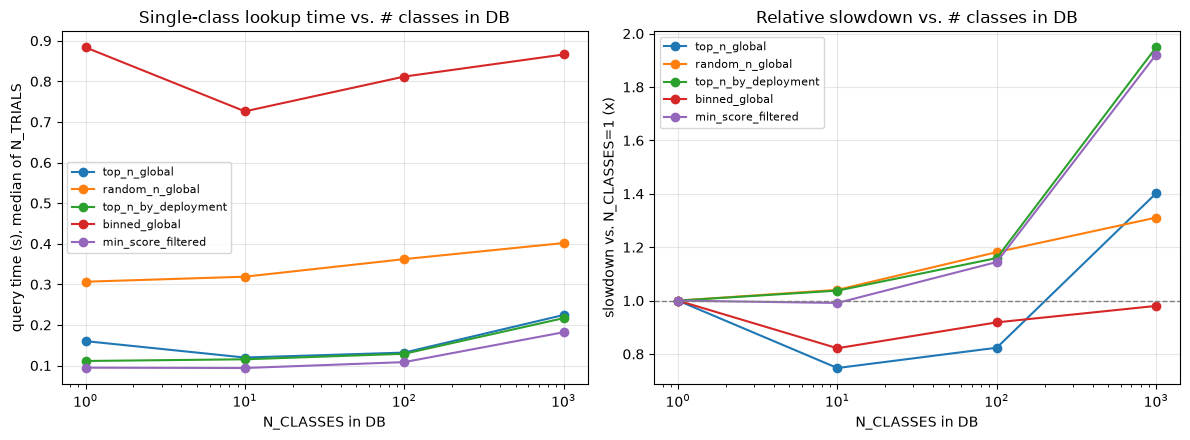

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for col in query_cols:
  axes[0].plot(results_df["n_classes"], results_df[col], marker="o", label=col)
axes[0].set_xscale("log")
axes[0].set_xlabel("N_CLASSES in DB")
axes[0].set_ylabel("query time (s), median of N_TRIALS")
axes[0].set_title("Single-class lookup time vs. # classes in DB")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for col in query_cols:
  axes[1].plot(
      slowdown_df["n_classes"],
      slowdown_df[f"{col}_slowdown_x"],
      marker="o",
      label=col,
  )
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xscale("log")
axes[1].set_xlabel("N_CLASSES in DB")
axes[1].set_ylabel("slowdown vs. N_CLASSES=1 (x)")
axes[1].set_title("Relative slowdown vs. # classes in DB")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## API examples
Retrieve all scores for eg certain deployments/recordings

In [ ]:
from ml_collections import config_dict

batch = db.get_scores(
    deployments_filter=config_dict.create(
        isin=dict(name=['scaling_deployment_00000', 'scaling_deployment_00001'])
    ),
    recordings_filter=config_dict.create(
        isin=dict(filename=[f"deployment_{first_deployment_id}/synthetic_new.wav"])
    )
)

# convert to pandas and add deployment and recording colmns
df = psi.add_deployment_metadata(db, batch.to_pandas())
df = psi.add_recording_metadata(db, df)
df.head(2).T

,0,1
filename,deployment_1/synthetic_new.wav,deployment_1/synthetic_new.wav
datetime,2026-09-26 10:00:00+00:00,2026-09-26 10:00:00+00:00
score_chunk_path,/tmp/parquet_scores_class_scaling_db/scores/de...,/tmp/parquet_scores_class_scaling_db/scores/de...
deployment_name,scaling_deployment_00000,scaling_deployment_00000
project,class_scaling_test,class_scaling_test
latitude,NaN,NaN
longitude,NaN,NaN
deployment_id,1,1
recording_id,2001,2001
start_time,0.0,3.0


In [21]:
db.count_windows()

10000006

In [53]:
# for each deployment, assign to one of 3 experimental groups
all_dpl = db.get_all_deployments()
db.add_extra_table_column("deployments", column_name="experimental_group", column_type=str)
for d in all_dpl:
    db.insert_deployment(
        name=d.name,
        project=d.project,
        experimental_group=np.random.choice(["A","B","C"])
    )
db.get_all_deployments()[:2]

[Deployment(id=1, name='scaling_deployment_00000', project='class_scaling_test', latitude=None, longitude=None, experimental_group='B'),
 Deployment(id=2, name='scaling_deployment_00001', project='class_scaling_test', latitude=None, longitude=None, experimental_group='A')]

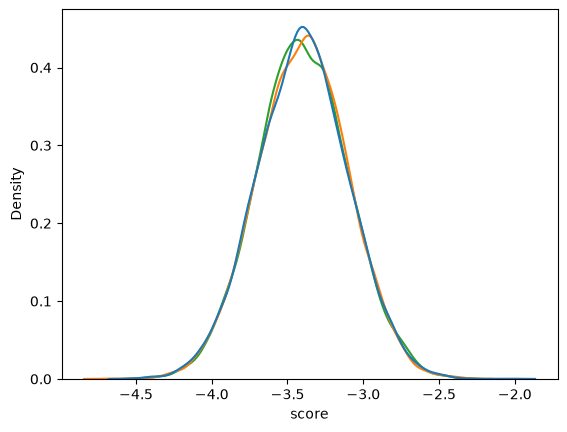

In [57]:
random_scores = db.select_scores(
    class_name=db.classes[0],
    selection="random",
    n=10000,
    by_deployment_fields=['experimental_group'],
    # by_deployment=True,
    # deployments_filter=config_dict.create(
    #     isin=dict(name=['scaling_deployment_00000', 'scaling_deployment_00001', 'scaling_deployment_00002'])
    # ),
)
import seaborn as sns
sns.kdeplot(data=random_scores, x="score", hue="experimental_group")
# no legend
import matplotlib.pyplot as plt
plt.legend([], [], frameon=False)

Select top-scoring per deployment for one class

<Axes: xlabel='score', ylabel='Density'>

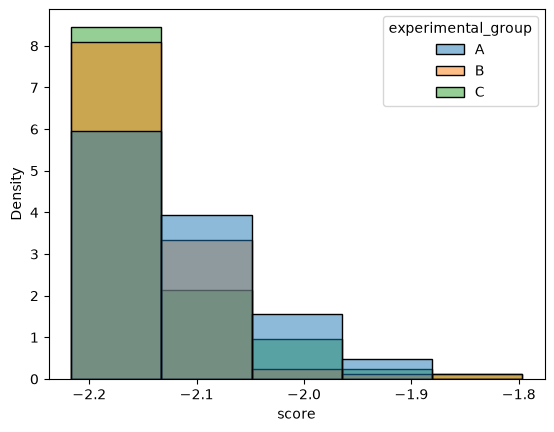

In [55]:
top_per_project = db.select_scores(
    class_name=db.classes[0],
    selection="top",
    by_deployment_fields=['experimental_group'],
    n=100,
)
sns.histplot(data=top_per_project, x="score", hue="experimental_group", bins=5, stat="density", common_norm=False)

In [58]:
# Cleanup. Comment out to inspect the on-disk DB/Parquet files afterward.
shutil.rmtree(SCALING_DB_PATH, ignore_errors=True)